# Beta Translator: Video Pose Tracking with MediaPipe

This notebook builds the first computer vision component of the **Beta Translator** project.

### Current pipeline

`climbing video → pose tracking → skeleton visualization → pose coordinates → wall reference frame`

The notebook produces three main outputs in the `outputs` directory:

1. `pose_output_h264.mp4` for visually checking the skeleton tracking.
2. `pose_coordinates.csv` for later hand and foot contact analysis.
3. `wall_reference.jpg` for manually annotating climbing holds.

At this stage, the goal is **not** to translate the beta yet. The goal is to obtain a reliable, structured representation of the climber's movement.


##### Copyright 2023 The MediaPipe Authors. All Rights Reserved.

In [19]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

## 1. Environment Setup

If running this locally, install all the dependencies by running `source ./setup.sh` in the terminal. Refer to `README.md` for more details.

Otherwise, run the block below. It is safe to run it even if `setup.sh` has already been executed.


In [20]:
# Checks if the setup.sh file has been run yet
from pathlib import Path
import subprocess

if Path(".setup_done").exists():
    print("Setup already done, skipping.")
else:
    subprocess.run(["bash", "setup.sh"], check=True)

Setup already done, skipping.


There should be a pretrained **Pose Landmarker Heavy** model installed. This heavy model is used here because accuracy is more important than real time speed for the initial climbing video experiments.

In [21]:
from pathlib import Path

OUTPUTS_DIR = Path("outputs")
MODELS_DIR = Path("models")
VIDEOS_DIR = Path("videos")

# Create directories just in case they don't exist
OUTPUTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)
VIDEOS_DIR.mkdir(exist_ok=True)

required_model_files = [
    "experiment_config.yml",
    "model_final.pth"
]

missing = [
    name for name in required_model_files
    if not (MODELS_DIR / name).is_file()
]

if missing:
    raise FileNotFoundError(
        f"Missing {missing} in {MODELS_DIR.resolve()}"
    )

print("Model files are ready.")

Model files are ready.


## 2. Imports and Visualization Helper

The helper function below draws the MediaPipe pose landmarks and skeleton connections on a video frame.

This visualization is primarily a **debugging tool**. Later stages of Beta Translator will use the numerical landmark coordinates rather than the rendered skeleton.


In [22]:
import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import Video
#from google.colab import files

from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from mediapipe.tasks.python.vision import drawing_utils
from mediapipe.tasks.python.vision import drawing_styles


def draw_landmarks_on_image(rgb_image, detection_result):
    pose_landmarks_list = detection_result.pose_landmarks
    annotated_image = np.copy(rgb_image)

    height, width, _ = annotated_image.shape

    for pose_landmarks in pose_landmarks_list:

        # Draw every landmark
        for landmark in pose_landmarks:
            x = int(landmark.x * width)
            y = int(landmark.y * height)

            if 0 <= x < width and 0 <= y < height:
                cv2.circle(
                    annotated_image,
                    (x, y),
                    5,
                    (255, 255, 0),
                    -1
                )

        # Draw every connection
        for connection in vision.PoseLandmarksConnections.POSE_LANDMARKS:
            start = pose_landmarks[connection.start]
            end = pose_landmarks[connection.end]

            x1 = int(start.x * width)
            y1 = int(start.y * height)

            x2 = int(end.x * width)
            y2 = int(end.y * height)

            cv2.line(
                annotated_image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

    return annotated_image


## 3. Upload the Climbing Video

Upload one short climbing video from a fixed camera.

For the first experiment, a video of roughly **10 to 20 seconds** is sufficient. The climber's full body should remain visible whenever possible.


In [23]:
from IPython.display import Video
VIDEO_NAME = "trial1.mp4"
VIDEO_FILE = str(VIDEOS_DIR / VIDEO_NAME)

if not Path(VIDEO_FILE).is_file():
    raise FileNotFoundError(f"Video not found: {Path(VIDEO_FILE).resolve()}")

cap = cv2.VideoCapture(VIDEO_FILE)
print("Opened:", cap.isOpened())

Opened: True


## 4. Run Pose Tracking and Create an Annotated Video

MediaPipe is configured in **VIDEO** mode. Each frame receives an increasing timestamp, which allows the model to use temporal tracking between frames.

The output of this section is `pose_output.mp4`, with the estimated skeleton drawn over the climber.


In [24]:
# Create a MediaPipe Pose Landmarker configured for video.
base_options = python.BaseOptions(
    model_asset_path=str(MODELS_DIR / "pose_landmarker.task")
)

options = vision.PoseLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.VIDEO,
    num_poses=1,
    min_pose_detection_confidence=0.2,
    min_pose_presence_confidence=0.2,
    min_tracking_confidence=0.2,
    output_segmentation_masks=False
)

detector = vision.PoseLandmarker.create_from_options(options)

# Open the uploaded video.
cap = cv2.VideoCapture(VIDEO_FILE)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if fps <= 0 or width <= 0 or height <= 0:
    raise ValueError("Could not read the uploaded video correctly.")

print(f"FPS: {fps:.2f}")
print(f"Video size: {width} x {height}")
print("Total frames:", frame_count)

# Create a video writer for the skeleton overlay.
output_path = "outputs/pose_output.mp4"
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

writer = cv2.VideoWriter(
    output_path,
    fourcc,
    fps,
    (width, height)
)

frame_index = 0

while True:
    ret, frame_bgr = cap.read()

    if not ret:
        break

    # OpenCV reads BGR images, while MediaPipe expects RGB.
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=frame_rgb
    )

    # MediaPipe VIDEO mode requires increasing timestamps.
    timestamp_ms = int(frame_index * 1000 / fps)

    result = detector.detect_for_video(
        mp_image,
        timestamp_ms
    )
    # if len(result.pose_landmarks) > 0:
    #   landmarks = result.pose_landmarks[0]

    #   lower_body = {
    #       23: "left hip",
    #       24: "right hip",
    #       25: "left knee",
    #       26: "right knee",
    #       27: "left ankle",
    #       28: "right ankle",
    #       29: "left heel",
    #       30: "right heel",
    #       31: "left foot",
    #       32: "right foot"
    #   }

    #   print(f"\nFrame {frame_index}")

    #   for index, name in lower_body.items():
    #       landmark = landmarks[index]
    #       print(
    #           f"{name:15} "
    #           f"visibility={landmark.visibility:.3f} "
    #           f"presence={landmark.presence:.3f}"
    #       )

    # Draw the estimated skeleton for visual inspection.
    annotated_rgb = draw_landmarks_on_image(
        frame_rgb,
        result
    )

    annotated_bgr = cv2.cvtColor(
        annotated_rgb,
        cv2.COLOR_RGB2BGR
    )

    writer.write(annotated_bgr)
    frame_index += 1

cap.release()
writer.release()
detector.close()

print("Pose tracking finished.")
print("Saved:", output_path)


FPS: 30.00
Video size: 720 x 1280
Total frames: 417


W0000 00:00:1791947290.589086 18468363 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791947290.632468 18468370 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Pose tracking finished.
Saved: outputs/pose_output.mp4


## 5. Preview the Skeleton Tracking Result

OpenCV's default MP4 encoding may not display reliably inside every browser. The next cell converts the result to H.264 and then displays it.

When reviewing the video, focus on whether the **wrists, feet, hips, and shoulders** remain aligned with the climber during movement.


In [25]:
# Convert to H.264 for more reliable playback in Colab/browser environments.
src = OUTPUTS_DIR / "pose_output.mp4"
dst = OUTPUTS_DIR / "pose_output_h264.mp4"

!ffmpeg -y -loglevel error -i "{src}" -vcodec libx264 "{dst}"

Video(
    "outputs/pose_output_h264.mp4",
    embed=True
)


## 6. Export Pose Coordinates for Every Frame

The skeleton video is useful for visual inspection, but Beta Translator ultimately needs numerical data.

This section reruns pose tracking and stores selected landmarks for each frame. We save:

* normalized `x` and `y` coordinates;
* MediaPipe `z`;
* pixel `x` and `y` coordinates;
* landmark visibility.

The **pixel coordinates** will be especially useful in the next stage because manually annotated climbing holds will also be represented in image pixels.


In [26]:
# Landmarks needed for climbing movement analysis.
important_landmarks = {
    "left_shoulder": 11,
    "right_shoulder": 12,
    "left_elbow": 13,
    "right_elbow": 14,
    "left_wrist": 15,
    "right_wrist": 16,
    "left_hip": 23,
    "right_hip": 24,
    "left_knee": 25,
    "right_knee": 26,
    "left_ankle": 27,
    "right_ankle": 28,
    "left_heel": 29,
    "right_heel": 30,
    "left_foot": 31,
    "right_foot": 32
}

# Create a fresh detector because the previous detector was closed.
base_options = python.BaseOptions(
    model_asset_path="models/pose_landmarker.task"
)

options = vision.PoseLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.VIDEO,
    num_poses=1,
    min_pose_detection_confidence=0.5,
    min_pose_presence_confidence=0.5,
    min_tracking_confidence=0.5,
    output_segmentation_masks=False
)

detector = vision.PoseLandmarker.create_from_options(options)

cap = cv2.VideoCapture(VIDEO_FILE)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

pose_data = []
frame_index = 0

while True:
    ret, frame_bgr = cap.read()

    if not ret:
        break

    frame_rgb = cv2.cvtColor(
        frame_bgr,
        cv2.COLOR_BGR2RGB
    )

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=frame_rgb
    )

    timestamp_ms = int(frame_index * 1000 / fps)

    result = detector.detect_for_video(
        mp_image,
        timestamp_ms
    )

    # Only create a row when MediaPipe detects a pose.
    if len(result.pose_landmarks) > 0:
        landmarks = result.pose_landmarks[0]

        row = {
            "frame": frame_index,
            "time_sec": frame_index / fps,
            "time_ms": timestamp_ms
        }

        for name, landmark_index in important_landmarks.items():
            landmark = landmarks[landmark_index]

            # Coordinates normalized relative to image width and height.
            row[f"{name}_x_norm"] = landmark.x
            row[f"{name}_y_norm"] = landmark.y

            # Relative depth estimate provided by MediaPipe.
            row[f"{name}_z"] = landmark.z

            # Pixel coordinates for later comparison with climbing holds.
            row[f"{name}_x_px"] = landmark.x * width
            row[f"{name}_y_px"] = landmark.y * height

            # Visibility helps identify potentially unreliable landmarks.
            row[f"{name}_visibility"] = landmark.visibility

        pose_data.append(row)

    frame_index += 1

cap.release()
detector.close()

pose_df = pd.DataFrame(pose_data)

pose_df.to_csv(
    "outputs/pose_coordinates.csv",
    index=False
)

print("Coordinate extraction finished.")
print("Frames with detected poses:", len(pose_df))
print("Saved: outputs/pose_coordinates.csv")

pose_df.head()


W0000 00:00:1791947316.906000 18469966 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791947316.926763 18469967 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Coordinate extraction finished.
Frames with detected poses: 417
Saved: outputs/pose_coordinates.csv


,frame,time_sec,time_ms,left_shoulder_x_norm,left_shoulder_y_norm,left_shoulder_z,left_shoulder_x_px,left_shoulder_y_px,left_shoulder_visibility,right_shoulder_x_norm,...,left_foot_z,left_foot_x_px,left_foot_y_px,left_foot_visibility,right_foot_x_norm,right_foot_y_norm,right_foot_z,right_foot_x_px,right_foot_y_px,right_foot_visibility
0,0,0.000000,0,0.408409,0.454279,0.089747,294.054222,581.477585,0.999988,0.489847,...,-0.357974,275.177071,877.907333,0.995056,0.535495,0.646417,0.262242,385.556474,827.414398,0.910683
1,1,0.033333,33,0.410563,0.455040,0.089752,295.605440,582.450981,0.999982,0.490443,...,-0.288351,275.887277,875.792694,0.994279,0.532444,0.648952,0.104058,383.359852,830.658035,0.906378
2,2,0.066667,66,0.419095,0.456175,0.106519,301.748042,583.903885,0.999977,0.492409,...,-0.289688,279.669943,874.075012,0.992087,0.530558,0.651545,0.071098,382.001710,833.977127,0.896169
3,3,0.100000,100,0.425105,0.458087,0.114677,306.075475,586.351433,0.999970,0.495646,...,-0.173901,279.483562,868.410492,0.991614,0.521355,0.653635,0.014415,375.375838,836.652908,0.901849
4,4,0.133333,133,0.433705,0.457889,0.121751,312.267859,586.098213,0.999964,0.497426,...,-0.253900,284.771783,868.632126,0.991246,0.521993,0.654983,-0.065227,375.834818,838.378601,0.904404


## 7. Extract a Reference Frame of the Climbing Wall

The next Beta Translator stage will require the locations of the climbing holds.

Choose a time when the climber blocks as few relevant holds as possible. The selected frame is saved as `wall_reference.jpg`.

Change `REFERENCE_TIME_SEC` and rerun the cell if another frame gives a clearer view of the route.


Saved frame 30 at 1.00 seconds.
Saved: outputs/wall_reference.jpg


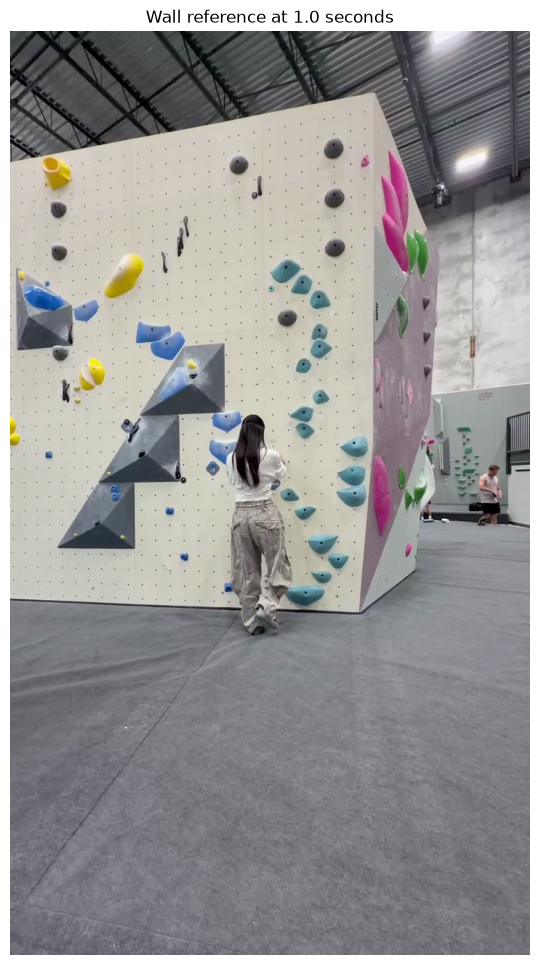

In [27]:
# Select a clear moment from the video.
REFERENCE_TIME_SEC = 1.0

cap = cv2.VideoCapture(VIDEO_FILE)

fps = cap.get(cv2.CAP_PROP_FPS)
reference_frame_number = int(REFERENCE_TIME_SEC * fps)

cap.set(
    cv2.CAP_PROP_POS_FRAMES,
    reference_frame_number
)

ret, reference_frame = cap.read()
cap.release()

if not ret:
    raise ValueError(
        "Could not read the requested reference frame. "
        "Try a smaller REFERENCE_TIME_SEC value."
    )

cv2.imwrite(
    "outputs/wall_reference.jpg",
    reference_frame
)

print(
    f"Saved frame {reference_frame_number} "
    f"at {REFERENCE_TIME_SEC:.2f} seconds."
)
print("Saved: outputs/wall_reference.jpg")

# Display the selected wall frame.
reference_rgb = cv2.cvtColor(
    reference_frame,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(8, 12))
plt.imshow(reference_rgb)
plt.axis("off")
plt.title(
    f"Wall reference at {REFERENCE_TIME_SEC:.1f} seconds"
)
plt.show()


## 8. Outputs and Next Step

After running the notebook from top to bottom, you should have:

| Output | Purpose |
| --- | --- |
| `pose_output_h264.mp4` | Inspect skeleton tracking quality |
| `pose_coordinates.csv` | Numerical body landmark trajectories |
| `wall_reference.jpg` | Reference image for hold annotation |

### Next development step

Manually annotate the relevant climbing holds on `wall_reference.jpg`, assign each hold an ID, and save its pixel coordinates.

The subsequent pipeline will be:

`pose coordinates + hold coordinates → hand/foot contact detection → movement sequence → structured beta`


## 9. Generate candidate hold annotations with the pretrained detector

This extension adapts the learned hold segmentation workflow in
[Indoor Climbing Hold and Route Segmentation](https://github.com/xiaoxiae/Indoor-Climbing-Hold-and-Route-Segmentation/blob/main/demo.ipynb).
Credit the original project in your report. Its repository uses GPL 3.0.

Run the original notebook first so `VIDEO_FILE` and `wall_reference.jpg` exist.
Use the raw video for contact annotation. The existing skeleton video is a separate visual aid.

Download the matching `experiment_config.yml` and `model_final.pth` for the authors' `Basic_Augmented_P2P3_DoubleTopK_NMS_2KIT` model from
[the authors' Kaggle dataset](https://www.kaggle.com/datasets/tomasslama/indoor-climbing-gym-hold-segmentation).
The notebook will ask you to upload both files. You do not need the training images or the route network for this experiment.

Predicted masks are candidates. Review missed holds, false detections, and occluded regions before treating them as annotations.
This extension has been checked structurally, but model inference has not been executed here because the pretrained files are not supplied.

In [28]:
# Install Detectron2 only if it is absent. Colab normally already has torch/torchvision.
# A source build can take several minutes. Run this cell by itself.
import sys
import subprocess
import importlib.util

import torch
import torchvision
print('Python:', sys.version.split()[0], 'Torch:', torch.__version__, 'Torchvision:', torchvision.__version__)
if importlib.util.find_spec('detectron2') is None:
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '--no-build-isolation',
        'git+https://github.com/facebookresearch/detectron2.git'
    ])
import detectron2
print('Detectron2 imported. If installation fails, inspect the build error before continuing.')

Python: 3.12.4 Torch: 2.14.1 Torchvision: 0.29.1
Detectron2 imported. If installation fails, inspect the build error before continuing.


Reference taken from: videos/trial1.mp4
Reference size: (1280, 720)


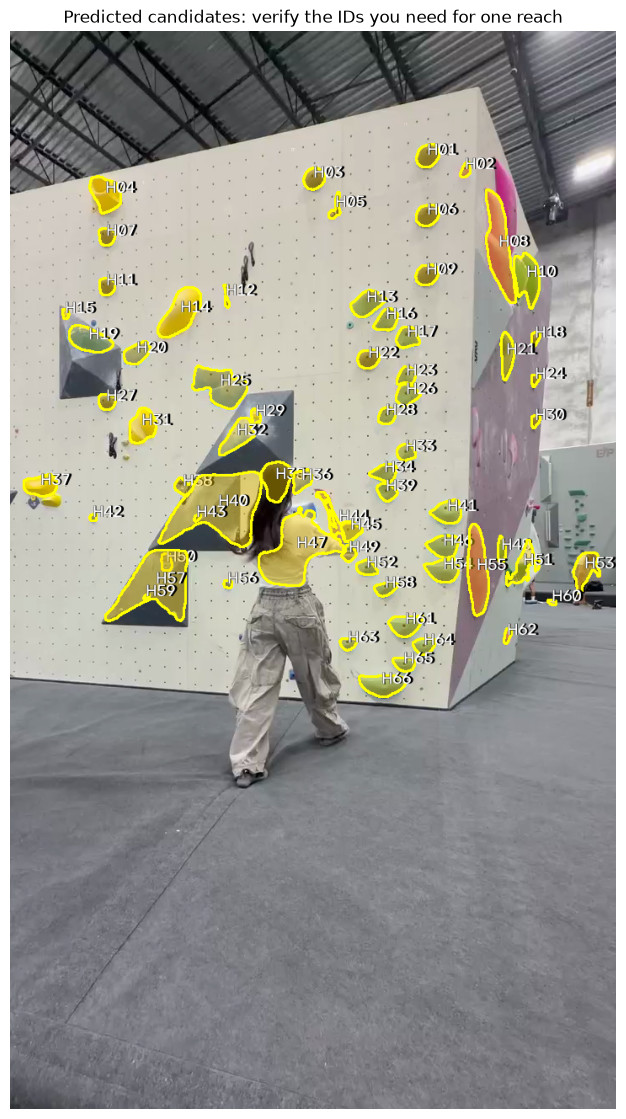

,model_index,class_id,class_name,score,cx_px,cy_px,x_min,y_min,x_max,y_max,area_px,source,review_status,hold_id
0,1,0,hold,0.996442,495.512563,147.753769,482,134,509,161,597,model_prediction,unreviewed,H01
1,36,0,hold,0.972285,540.583333,164.898810,534,155,546,173,168,model_prediction,unreviewed,H02
2,10,0,hold,0.994214,360.578544,174.923372,348,162,373,188,522,model_prediction,unreviewed,H03
3,23,0,hold,0.987603,113.229008,192.764207,94,172,131,216,1179,model_prediction,unreviewed,H04
4,37,0,hold,0.961767,386.211982,209.732719,378,191,392,222,217,model_prediction,unreviewed,H05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,40,0,hold,0.944675,590.351145,717.366412,586,708,595,727,131,model_prediction,unreviewed,H62
62,8,0,hold,0.994362,401.169421,726.859504,391,721,412,735,242,model_prediction,unreviewed,H63
63,25,0,hold,0.981525,491.516746,729.543062,478,721,505,740,418,model_prediction,unreviewed,H64
64,28,0,hold,0.980510,467.662011,751.097765,454,744,480,760,358,model_prediction,unreviewed,H65


IDs belong to this prediction run. Changing the frame/model/threshold may change them.


In [30]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from detectron2.config import get_cfg
from detectron2.engine import DefaultPredictor

# Use the first frame of the current video as the reference.
reference_cap = cv2.VideoCapture(VIDEO_FILE)
ok, reference_frame = reference_cap.read()
reference_cap.release()

if not ok:
    raise ValueError(f"Could not read the first frame of {VIDEO_FILE}.")

wall_image = reference_frame.copy()

print("Reference taken from:", VIDEO_FILE)
print("Reference size:", wall_image.shape[:2])

hold_cfg = get_cfg()
hold_cfg.merge_from_file(str(MODELS_DIR / 'experiment_config.yml'))
hold_cfg.MODEL.WEIGHTS = str(MODELS_DIR / 'model_final.pth')
# CPU is slower but avoids requiring a GPU build for this single image.
hold_cfg.MODEL.DEVICE = 'cpu'
SCORE_THRESHOLD = 0.70  # Starting value, not a validated threshold for your wall.
hold_cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = SCORE_THRESHOLD
hold_predictor = DefaultPredictor(hold_cfg)
hold_instances = hold_predictor(wall_image)['instances'].to('cpu')
if not hold_instances.has('pred_masks'):
    raise ValueError('The loaded model did not return instance masks. Check the model/config pair.')

def build_hold_candidates(masks, scores, classes):
    """Keep pixel geometry at original image size and assign deterministic IDs per run."""
    unsorted = []
    for model_index, (mask, score, class_id) in enumerate(zip(masks, scores, classes)):
        ys, xs = np.nonzero(mask)
        if len(xs) == 0:
            continue
        unsorted.append((float(ys.mean()), float(xs.mean()), model_index, {
            'model_index': int(model_index), 'class_id': int(class_id),
            'class_name': {0: 'hold', 1: 'volume'}.get(int(class_id), 'other'),
            'score': float(score), 'cx_px': float(xs.mean()), 'cy_px': float(ys.mean()),
            'x_min': int(xs.min()), 'y_min': int(ys.min()),
            'x_max': int(xs.max()), 'y_max': int(ys.max()), 'area_px': int(len(xs)),
            'source': 'model_prediction', 'review_status': 'unreviewed'
        }))
    records, mask_map = [], {}
    for i, (_, _, model_index, record) in enumerate(sorted(unsorted, key=lambda x: x[:3]), 1):
        record['hold_id'] = f'H{i:02d}'
        records.append(record)
        mask_map[record['hold_id']] = np.asarray(masks[model_index], dtype=bool)
    return records, mask_map

import uuid
candidate_run_id = uuid.uuid4().hex
candidate_records, candidate_masks = build_hold_candidates(
    hold_instances.pred_masks.numpy(), hold_instances.scores.numpy(),
    hold_instances.pred_classes.numpy()
)
if not candidate_records:
    raise ValueError('No candidates. Inspect the reference image and try a lower threshold, such as 0.5.')

# If H is none, render as if holds never change coordinates in camera space
def render_holds(frame, ids, H=None):
    if frame.shape[:2] != wall_image.shape[:2]:
        raise ValueError('Video and reference image dimensions differ. Do not mix resized coordinates.')
    result = frame.copy()
    h, w = frame.shape[:2]
    for hold_id in ids:
        record = next(r for r in candidate_records if r['hold_id'] == hold_id)
        mask = candidate_masks[hold_id]
        if H is not None:
            mask = cv2.warpPerspective(mask.astype(np.uint8), H, (w, h),
                                       flags=cv2.INTER_NEAREST).astype(bool)
            if not mask.any():
                continue
            ys, xs = np.nonzero(mask)
            xy = (int(xs.mean()), int(ys.mean()))
        else:
            xy = (int(record['cx_px']), int(record['cy_px']))
        result[mask] = (0.6 * result[mask] + 0.4 * np.array([0, 210, 255])).astype(np.uint8)
        contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(result, contours, -1, (0, 255, 255), 2)
        cv2.putText(result, hold_id, xy, cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 0, 0), 4)
        cv2.putText(result, hold_id, xy, cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 255), 1)
    return result

plt.figure(figsize=(10, 14))
plt.imshow(cv2.cvtColor(render_holds(wall_image, candidate_masks), cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title('Predicted candidates: verify the IDs you need for one reach')
plt.show()
display(pd.DataFrame(candidate_records))
print('IDs belong to this prediction run. Changing the frame/model/threshold may change them.')

In [34]:
sift = cv2.SIFT_create(nfeatures=4000)
bf = cv2.BFMatcher(cv2.NORM_L2)

# Optional: polygon (in frame-0 pixels) around the flat wall face with the route,
# e.g. np.array([[x, y], [x, y], ...]). None = use the whole frame.
WALL_ROI = None

# Builds a mask that blacks out the climber
def climber_exclusion_mask(shape, frame_idx, pad=60):
    # 255 = usable wall pixels, 0 = box around the climber
    mask = np.full(shape[:2], 255, np.uint8)
    row = pose_df[pose_df.frame == frame_idx]
    if len(row):
        r = row.iloc[0]
        xs = [r[c] for c in r.index if c.endswith('_x_px')]
        ys = [r[c] for c in r.index if c.endswith('_y_px')]
        mask[max(0, int(min(ys)) - pad):int(max(ys)) + pad,
             max(0, int(min(xs)) - pad):int(max(xs)) + pad] = 0
    return mask

# Finds SIFT features in one frame and matches them to frame-0 features
def estimate_H_ref_to_frame(ref_kp, ref_des, frame_bgr, frame_idx, min_inliers=25):
    gray = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY)
    kp, des = sift.detectAndCompute(gray, climber_exclusion_mask(gray.shape, frame_idx))
    if des is None or len(kp) < 10:
        return None, 0
    pairs = bf.knnMatch(ref_des, des, k=2)
    good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < 0.75 * p[1].distance]
    if len(good) < min_inliers:
        return None, len(good)
    src = np.float32([ref_kp[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, inliers = cv2.findHomography(src, dst, cv2.RANSAC, 4.0)
    if H is None:
        return None, 0
    n = int(inliers.sum())
    return (H if n >= min_inliers else None), n

# Features in the reference frame (frame 0), excluding the climber and anything outside the ROI.
ref_gray = cv2.cvtColor(wall_image, cv2.COLOR_BGR2GRAY)
ref_mask = climber_exclusion_mask(ref_gray.shape, 0)
if WALL_ROI is not None:
    roi = np.zeros_like(ref_mask)
    cv2.fillPoly(roi, [WALL_ROI.astype(np.int32)], 255)
    ref_mask = cv2.bitwise_and(ref_mask, roi)
ref_kp, ref_des = sift.detectAndCompute(ref_gray, ref_mask)

# Get homography for each frame
homographies = {}          # frame index -> (H, inlier_count, 'ok' | 'reused')
last_H = np.eye(3)
cap = cv2.VideoCapture(VIDEO_FILE)
i = 0
while True:
    ok, f = cap.read()
    if not ok:
        break
    H, n = estimate_H_ref_to_frame(ref_kp, ref_des, f, i)
    if H is None:
        H, status = last_H, 'reused'   # fall back to the previous frame's transform
    else:
        last_H, status = H, 'ok'
    homographies[i] = (H, n, status)
    i += 1
cap.release()

bad = [k for k, v in homographies.items() if v[2] != 'ok']
print(f"{len(homographies)} frames, {len(bad)} fell back to the previous transform")
print("min/median inliers:", min(v[1] for v in homographies.values()),
      int(np.median([v[1] for v in homographies.values()])))

417 frames, 0 fell back to the previous transform
min/median inliers: 157 521


## 10. Review the holds needed for one reach

Enter the IDs of all starting supports and the destination hold below. Include only real holds or usable volumes on the selected route.
You can reject false detections simply by leaving them out. Review the mask boundary of every selected candidate.
If a needed hold is missing or badly segmented, first try another reference frame where it is visible, or change the threshold and rerun section 9.
This notebook does not silently repair a missing mask. A manual correction would be needed if the detector cannot recover it.

Use a stationary camera. If hold outlines drift on the video frames below, stop and align the video before assigning contacts.
Do not rerun segmentation after assigning contacts without repeating the review.

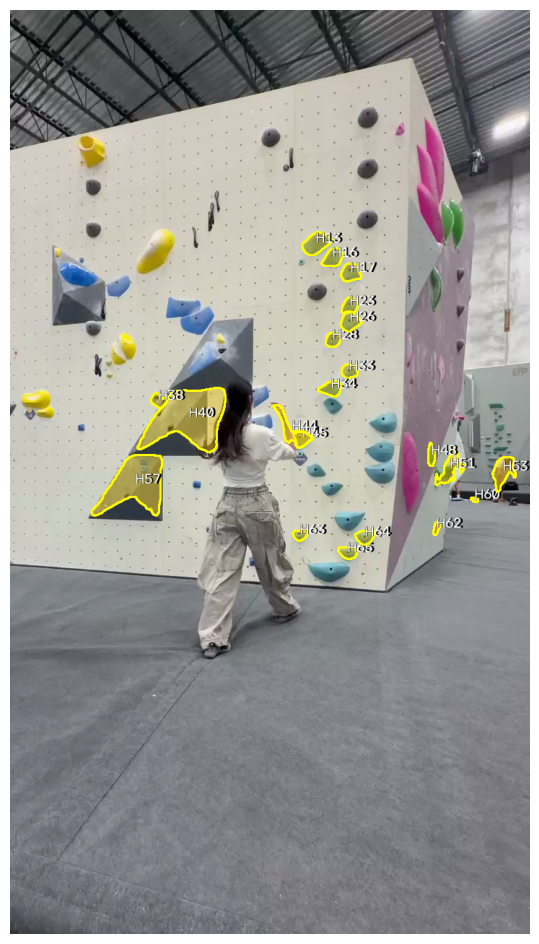

In [35]:
# Replace the empty list with IDs visible in YOUR prediction, e.g. ['H03', 'H07', 'H12'].
SELECTED_HOLD_IDS = [
    'H65', 'H64', 'H62', 'H60', 'H63', 'H57', 'H51',
    'H53', 'H45', 'H40', 'H48', 'H44', 'H33', 'H38',
    'H34', 'H28', 'H26', 'H23', 'H17', 'H16', 'H13'
]
if not SELECTED_HOLD_IDS:
    raise ValueError('Enter the relevant predicted hold IDs in SELECTED_HOLD_IDS, then rerun.')
if len(set(SELECTED_HOLD_IDS)) != len(SELECTED_HOLD_IDS):
    raise ValueError('Remove duplicate hold IDs.')
invalid = set(SELECTED_HOLD_IDS) - set(candidate_masks)
if invalid:
    raise ValueError(f'Unknown hold IDs: {invalid}')
selected_hold_ids = list(SELECTED_HOLD_IDS)
reviewed_run_id = candidate_run_id
reviewed_records = [dict(r, review_status='accepted') for r in candidate_records if r['hold_id'] in selected_hold_ids]
plt.figure(figsize=(8, 12))
plt.imshow(cv2.cvtColor(render_holds(wall_image, selected_hold_ids), cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## 11. Select before and after frames, then label four limb contacts

Choose one clear movement, preferably one hand moving while the other limbs remain visible.
Use the slider and single frame buttons to inspect the raw video. Click **Set BEFORE** at a stable position before the reach and **Set AFTER** once the moving limb has reached its destination.
The labels describe the selected frames only. They do not establish exact release/arrival times or continuous contact between them.

Left and right refer to the climber's anatomy. Assign a hold only when visible evidence supports contact, not merely because a wrist is close to it.
Choose `unknown` for occluded contacts, `free` for a limb off the wall, and `wall_contact` for a visible smear outside the selected holds.

In [36]:
import ipywidgets as widgets
from IPython.display import display

if reviewed_run_id != candidate_run_id:
    raise ValueError('Segmentation changed. Rerun hold review first.')
contact_form_run_id = reviewed_run_id
annotation_cap = cv2.VideoCapture(VIDEO_FILE)
annotation_fps = float(annotation_cap.get(cv2.CAP_PROP_FPS))
annotation_count = int(annotation_cap.get(cv2.CAP_PROP_FRAME_COUNT))
annotation_cap.release()
if annotation_count < 2 or annotation_fps <= 0:
    raise ValueError('Could not read the video metadata.')

def read_annotation_frame(index):
    cap = cv2.VideoCapture(VIDEO_FILE)
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(index))
    ok, frame = cap.read()
    cap.release()
    if not ok:
        raise ValueError(f'Could not read frame {index}.')
    return frame

frame_slider = widgets.IntSlider(value=0, min=0, max=annotation_count-1,
    description='Frame', continuous_update=False, layout=widgets.Layout(width='540px'))
frame_image = widgets.Image(format='jpeg',
    layout=widgets.Layout(width='338px', height='600px', object_fit='contain'))
frame_info = widgets.HTML()
chosen_info = widgets.HTML('Choose both frames.')
chosen_frames = {'before': None, 'after': None}

def show_annotation_frame(change=None):
    i = frame_slider.value
    frame = render_holds(read_annotation_frame(i), selected_hold_ids, homographies[i][0])
    ok, encoded = cv2.imencode('.jpg', frame)
    if not ok:
        raise ValueError('Frame encoding failed.')
    frame_image.value = encoded.tobytes()
    frame_info.value = f'Frame {i} | {i/annotation_fps:.3f} seconds | original pixel coordinates'

def choose_endpoint(name):
    chosen_frames[name] = frame_slider.value
    chosen_info.value = f"BEFORE: {chosen_frames['before']} | AFTER: {chosen_frames['after']}"

previous_button = widgets.Button(description='Previous frame')
next_button = widgets.Button(description='Next frame')
before_button = widgets.Button(description='Set BEFORE')
after_button = widgets.Button(description='Set AFTER')
previous_button.on_click(lambda _: setattr(frame_slider, 'value', max(0, frame_slider.value-1)))
next_button.on_click(lambda _: setattr(frame_slider, 'value', min(annotation_count-1, frame_slider.value+1)))
before_button.on_click(lambda _: choose_endpoint('before'))
after_button.on_click(lambda _: choose_endpoint('after'))
frame_slider.observe(show_annotation_frame, names='value')

limbs = ['left_hand', 'right_hand', 'left_foot', 'right_foot']
contact_choices = ['unknown', 'free', 'wall_contact'] + selected_hold_ids
contact_widgets = {}
rows = [widgets.HTML('<b>Limb | BEFORE contact | AFTER contact</b>')]
for limb in limbs:
    contact_widgets[limb] = {
        phase: widgets.Dropdown(options=contact_choices, value='unknown', layout=widgets.Layout(width='170px'))
        for phase in ['before', 'after']
    }
    rows.append(widgets.HBox([widgets.Label(limb, layout=widgets.Layout(width='120px')),
        contact_widgets[limb]['before'], contact_widgets[limb]['after']]))
moving_limb = widgets.Dropdown(options=limbs, description='Moving limb', style={'description_width': 'initial'})
annotation_notes = widgets.Textarea(description='Notes',
    placeholder='Occlusion, uncertainty, or other limbs moving during the interval',
    layout=widgets.Layout(width='540px', height='60px'))
controls = widgets.VBox([
    frame_slider,
    widgets.HBox([previous_button, next_button, before_button, after_button]),
    frame_info, chosen_info,
    moving_limb, *rows, annotation_notes
], layout=widgets.Layout(width='560px'))

display(widgets.HBox([frame_image, controls],
    layout=widgets.Layout(align_items='flex-start')))
show_annotation_frame()